###Section 1：Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import spectrogram as sci_spectrogram
from pathlib import Path

SAMPLE_RATE = 8000

WIN_SEC = 1.0
WIN_SAMPLES = int(SAMPLE_RATE * WIN_SEC)

AUDIO_FILES = {
    "silence": "silence.wav",
    "single_speaker": "single_speaker.wav",
    "multiple_speakers": "multiple_speakers.wav",
}

COLORS = {
    "silence": "tab:blue",
    "single_speaker": "tab:green",
    "multiple_speakers": "tab:red",
}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

### Section 2: Load Files

In [ ]:
DATA_DIR = Path(".")

def load_wav(path, keep_sec=None):
    """
    Load WAV -> (int16_array, float_array_normalized_to_-1_to_1)
    """
    sr, raw = wavfile.read(path)

    if sr != SAMPLE_RATE:
        raise ValueError(f"{path}: expected {SAMPLE_RATE} Hz, got {sr} Hz")

    if raw.ndim > 1:
        raw = raw[:, 0]

    if keep_sec is not None:
        raw = raw[: int(keep_sec * sr)]

    int16_audio = raw.astype(np.int16)
    float_audio = int16_audio.astype(np.float64) / 32768.0
    return int16_audio, float_audio


recordings_i16 = {}
recordings_f32 = {}

for label, fname in AUDIO_FILES.items():
    path = DATA_DIR / fname
    audio_i16, audio_f32 = load_wav(path)
    recordings_i16[label] = audio_i16
    recordings_f32[label] = audio_f32

    duration = len(audio_i16) / SAMPLE_RATE
    print(f"{label:18s} | samples = {len(audio_i16):6d} | duration = {duration:.2f}s | file = {path}")

silence            | samples = 240000 | duration = 30.00s | file = silence.wav
single_speaker     | samples = 240000 | duration = 30.00s | file = single_speaker.wav
multiple_speakers  | samples = 240000 | duration = 30.00s | file = multiple_speakers.wav


In [ ]:
# Sanity Check

for label, audio in recordings_f32.items():
    print(
        f"{label:18s} | min = {audio.min(): .4f} | max = {audio.max(): .4f} | mean abs = {np.mean(np.abs(audio)):.4f}"
    )

silence            | min = -0.0085 | max =  0.0083 | mean abs = 0.0016
single_speaker     | min = -0.5344 | max =  0.4556 | mean abs = 0.0315
multiple_speakers  | min = -0.8018 | max =  0.6213 | mean abs = 0.0484


### Section 3: Time-Series Waveforms

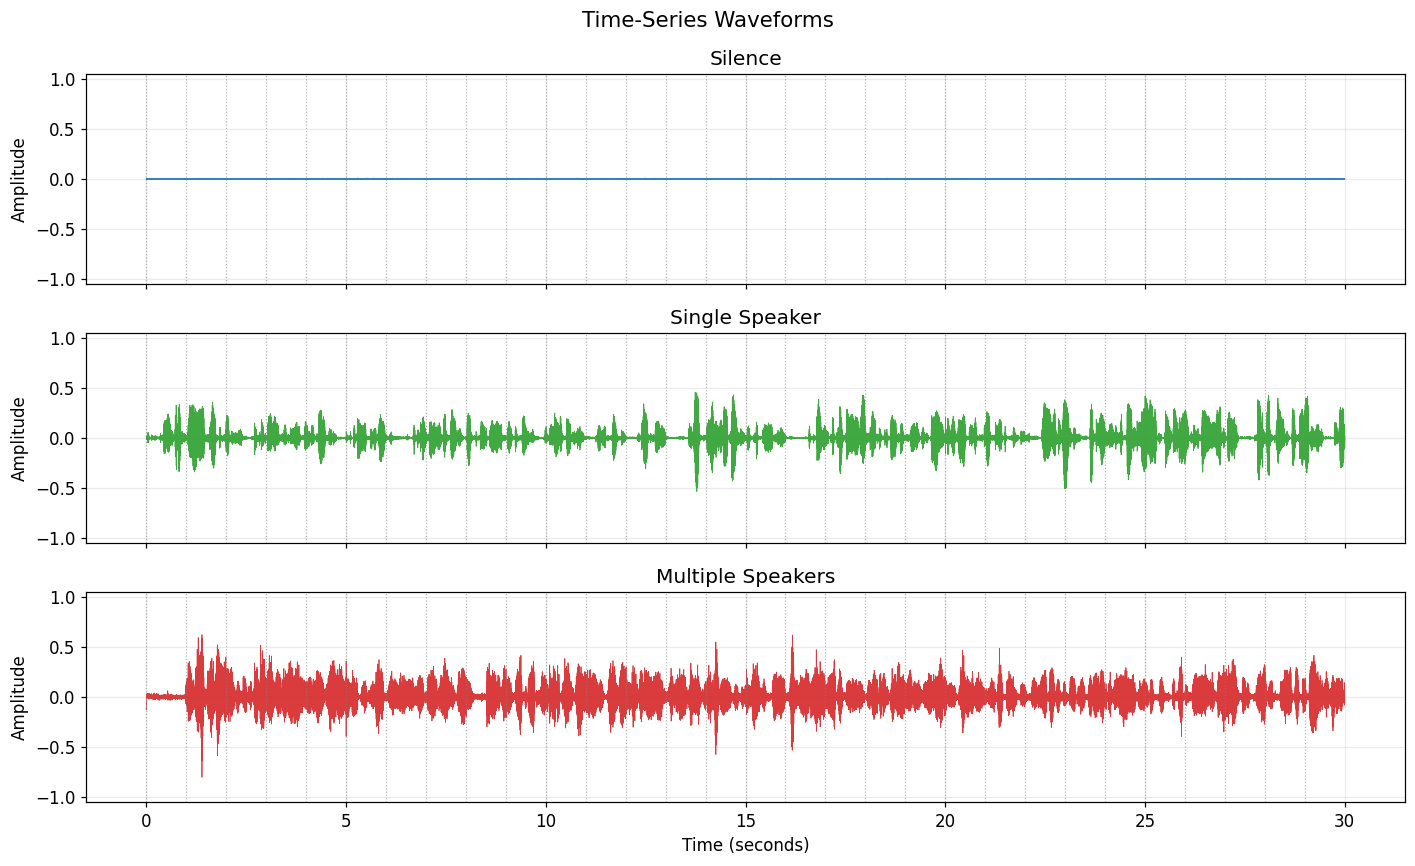

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

for ax, (label, audio) in zip(axes, recordings_f32.items()):
    t = np.arange(len(audio)) / SAMPLE_RATE

    ax.plot(t, audio, color=COLORS[label], linewidth=0.5, alpha=0.9)

    for k in np.arange(0, t[-1] + 1e-9, WIN_SEC):
        ax.axvline(k, color="gray", linewidth=0.8, linestyle=":", alpha=0.6)

    ax.set_ylabel("Amplitude")
    ax.set_ylim(-1.05, 1.05)
    ax.set_title(label.replace("_", " ").title())

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("Time-Series Waveforms", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

### Section 4: STFT Spectrograms

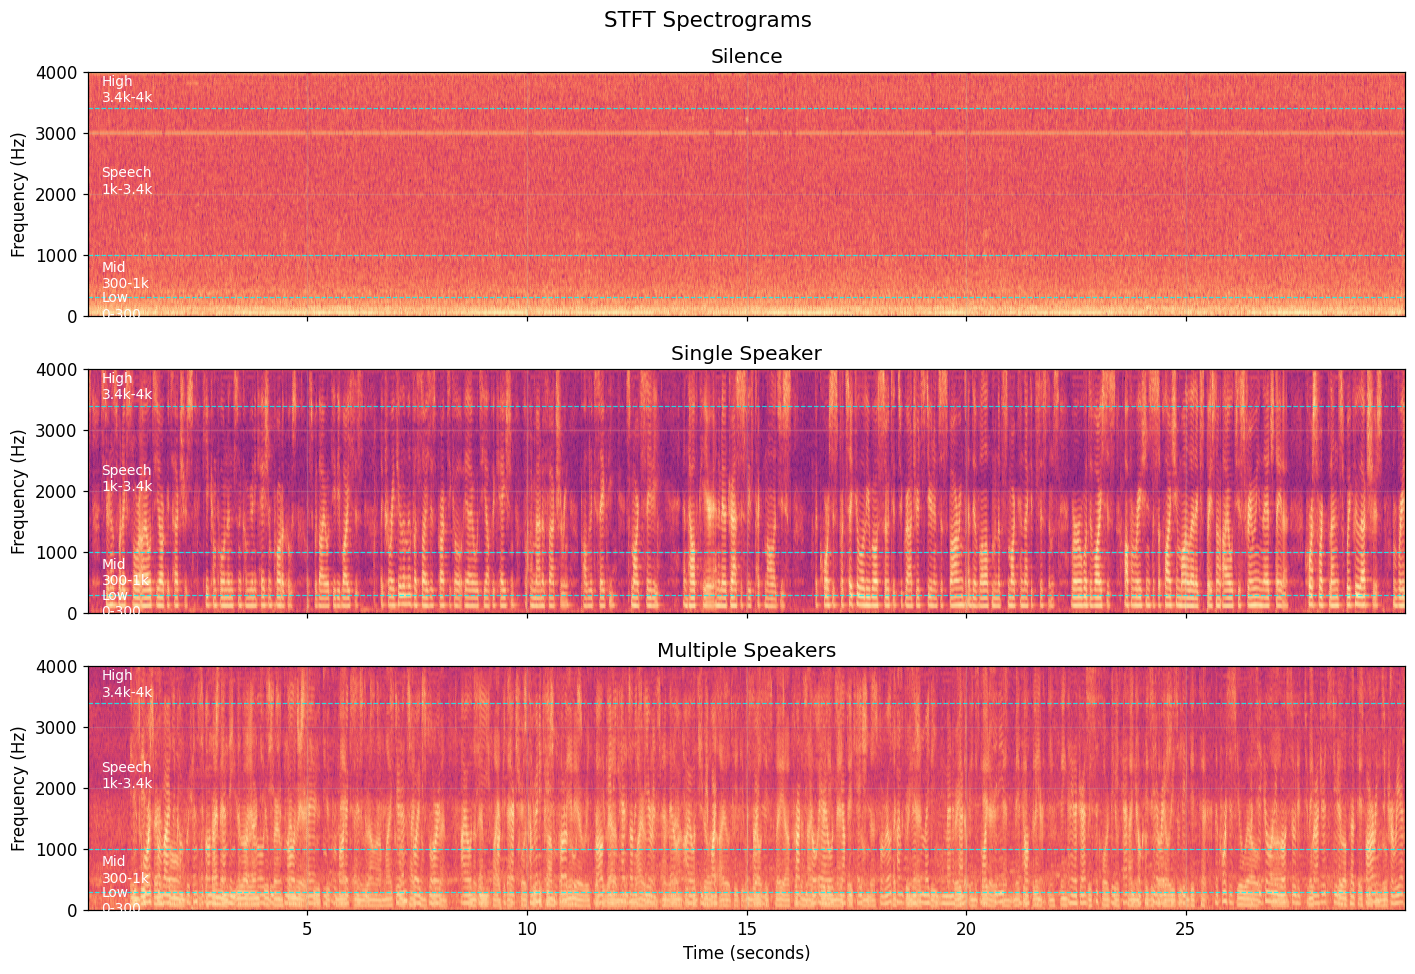

In [ ]:
BAND_LINES = [300, 1000, 3400]
BAND_CENTRES = [150, 650, 2200, 3700]
BAND_LABELS = ["Low\n0-300", "Mid\n300-1k", "Speech\n1k-3.4k", "High\n3.4k-4k"]

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

for ax, (label, audio) in zip(axes, recordings_f32.items()):
    f_bins, t_bins, Sxx = sci_spectrogram(
        audio,
        fs=SAMPLE_RATE,
        nperseg=256,
        noverlap=192,
        window="hann",
        scaling="density",
        mode="magnitude"
    )

    Sxx_db = 20 * np.log10(Sxx + 1e-10)

    im = ax.pcolormesh(
        t_bins,
        f_bins,
        Sxx_db,
        shading="gouraud",
        cmap="magma"
    )

    for y in BAND_LINES:
        ax.axhline(y, color="cyan", linestyle="--", linewidth=0.8, alpha=0.8)

    for yc, txt in zip(BAND_CENTRES, BAND_LABELS):
        ax.text(
            0.01, yc,
            txt,
            color="white",
            fontsize=9,
            va="center",
            ha="left",
            transform=ax.get_yaxis_transform()
        )

    ax.set_ylim(0, 4000)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(label.replace("_", " ").title())

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("STFT Spectrograms", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

### Section 5: Feature Extraction

In [ ]:
import pandas as pd
import numpy as np

# 1-sec window + 10 subsegments

CLASS_ORDER = ["silence", "single_speaker", "multiple_speakers"]

WIN_SEC = 1.0
STRIDE_SEC = 1.0
N_SUBSEGMENTS = 10

feature_cols = [
    "mean_abs_amp",
    "rms_energy",
    "peak_amp",
    "variance",
    "zero_crossing_rate",
    "sub_rms_std",
    "sub_rms_range",
    "active_ratio",
    "max_active_streak",
]

def zero_crossing_rate(x):
    x = np.asarray(x)
    signs = np.sign(x)
    signs[signs == 0] = 1
    return np.mean(signs[1:] != signs[:-1])


def extract_features_from_window(x):
    x = np.asarray(x)

    row = {}

    # Global time-domain features
    row["mean_abs_amp"] = np.mean(np.abs(x))
    row["rms_energy"] = np.sqrt(np.mean(x ** 2))
    row["peak_amp"] = np.max(np.abs(x))
    row["variance"] = np.var(x)
    row["zero_crossing_rate"] = zero_crossing_rate(x)

    # Split 1-sec window into 10 subsegments
    seg_len = len(x) // N_SUBSEGMENTS
    sub_rms = []

    for i in range(N_SUBSEGMENTS):
        start = i * seg_len
        end = start + seg_len
        seg = x[start:end]
        sub_rms.append(np.sqrt(np.mean(seg ** 2)))

    sub_rms = np.array(sub_rms)

    # Temporal structure features
    row["sub_rms_std"] = np.std(sub_rms)
    row["sub_rms_range"] = np.max(sub_rms) - np.min(sub_rms)

    active_threshold = max(0.002, 0.25 * np.mean(sub_rms))
    active_flags = sub_rms > active_threshold

    row["active_ratio"] = np.mean(active_flags)

    # Longest continuous active run
    max_streak = 0
    current_streak = 0

    for is_active in active_flags:
        if is_active:
            current_streak += 1
            max_streak = max(max_streak, current_streak)
        else:
            current_streak = 0

    row["max_active_streak"] = max_streak

    return row


def extract_features_for_recording(label, audio, sr=SAMPLE_RATE):
    win_samples = int(WIN_SEC * sr)
    stride_samples = int(STRIDE_SEC * sr)

    rows = []
    start = 0
    window_id = 0

    while start + win_samples <= len(audio):
        end = start + win_samples
        window = audio[start:end]

        feats = extract_features_from_window(window)

        feats["label"] = label
        feats["window_id"] = window_id
        feats["start_sec"] = start / sr
        feats["end_sec"] = end / sr

        rows.append(feats)

        start += stride_samples
        window_id += 1

    return rows


all_rows = []

for label in CLASS_ORDER:
    audio = recordings_f32[label]
    rows = extract_features_for_recording(label, audio)
    all_rows.extend(rows)

features_df = pd.DataFrame(all_rows)

print("Feature table shape:", features_df.shape)
features_df.head()

Feature table shape: (90, 13)


,mean_abs_amp,rms_energy,peak_amp,variance,zero_crossing_rate,sub_rms_std,sub_rms_range,active_ratio,max_active_streak,label,window_id,start_sec,end_sec
0,0.001626,0.002027,0.007324,0.000004,0.156770,0.000167,0.000699,0.5,3,silence,0,0.0,1.0
1,0.001639,0.002024,0.006836,0.000004,0.149144,0.000224,0.000689,0.5,2,silence,1,1.0,2.0
2,0.001350,0.001705,0.006592,0.000003,0.188274,0.000182,0.000638,0.1,1,silence,2,2.0,3.0
3,0.001602,0.002012,0.007080,0.000004,0.158645,0.000224,0.000819,0.5,4,silence,3,3.0,4.0
4,0.001747,0.002160,0.007080,0.000005,0.142018,0.000168,0.000565,0.8,4,silence,4,4.0,5.0


In [ ]:
features_df["label"].value_counts()

,count
label,
silence,30
single_speaker,30
multiple_speakers,30


In [ ]:
features_df.groupby("label")[feature_cols].mean().round(5)

,mean_abs_amp,rms_energy,peak_amp,variance,zero_crossing_rate,sub_rms_std,sub_rms_range,active_ratio,max_active_streak
label,,,,,,,,,
multiple_speakers,0.04835,0.06802,0.39074,0.00492,0.16457,0.02236,0.07508,0.98333,9.66667
silence,0.00160,0.00199,0.00714,0.00000,0.15747,0.00018,0.00060,0.46000,3.63333
single_speaker,0.03153,0.05126,0.33702,0.00285,0.24729,0.02722,0.08406,0.85000,7.50000


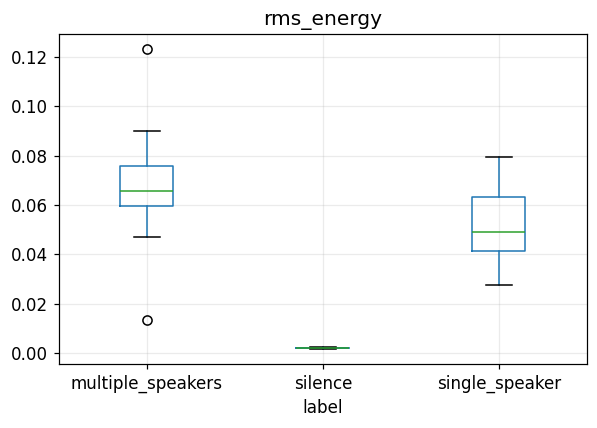

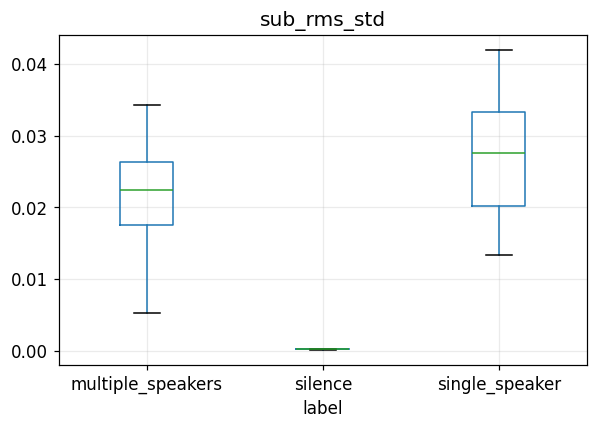

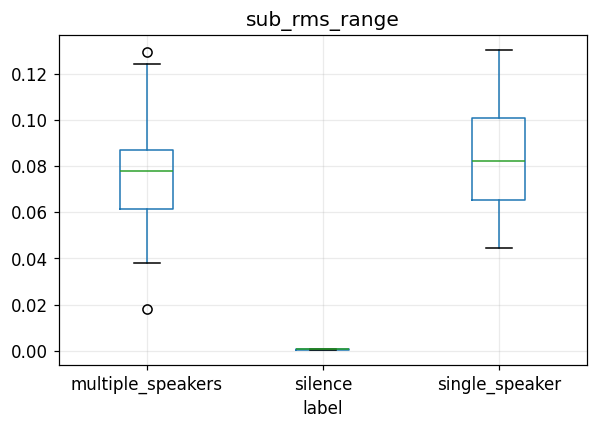

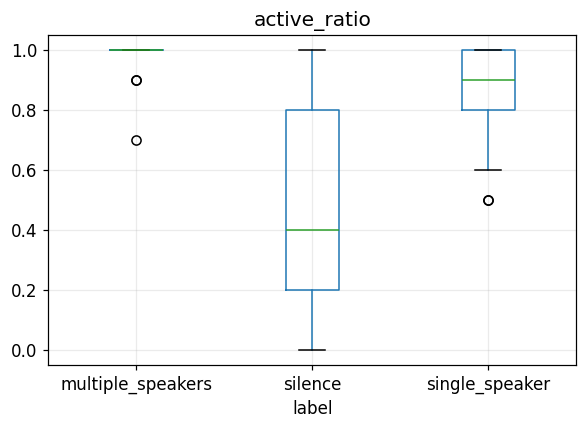

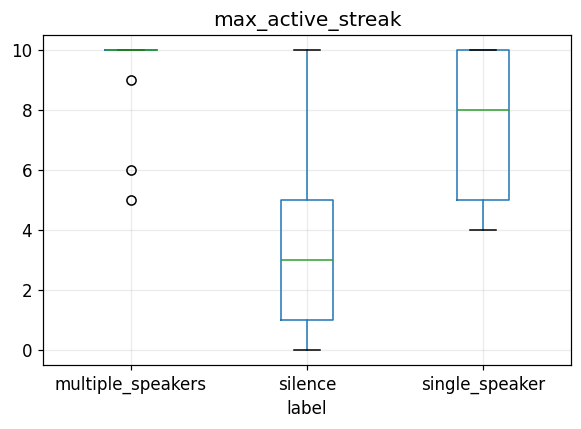

In [ ]:
import matplotlib.pyplot as plt

key_features = [
    "rms_energy",
    "sub_rms_std",
    "sub_rms_range",
    "active_ratio",
    "max_active_streak",
]

for col in key_features:
    features_df.boxplot(column=col, by="label", figsize=(6, 4))
    plt.title(col)
    plt.suptitle("")
    plt.show()

### Section 6: Train the MLP and Evaluate

In [ ]:
# 1-sec window + lightweight temporal features


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import numpy as np

X = features_df[feature_cols].copy()
y = features_df["label"].copy()

print("Label counts:")
print(y.value_counts())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature columns:")
print(feature_cols)

Label counts:
label
silence              30
single_speaker       30
multiple_speakers    30
Name: count, dtype: int64

X shape: (90, 9)
y shape: (90,)

Feature columns:
['mean_abs_amp', 'rms_energy', 'peak_amp', 'variance', 'zero_crossing_rate', 'sub_rms_std', 'sub_rms_range', 'active_ratio', 'max_active_streak']


In [ ]:
# encode label
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Class mapping:")
for i, cls in enumerate(label_encoder.classes_):
    print(i, "->", cls)

# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("Train label counts:", np.bincount(y_train))
print("Test label counts:", np.bincount(y_test))

Class mapping:
0 -> multiple_speakers
1 -> silence
2 -> single_speaker
Train label counts: [21 21 21]
Test label counts: [9 9 9]


In [ ]:
# Train MLP

mlp_model = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(8,),
        activation="relu",
        solver="lbfgs",
        alpha=0.01,
        max_iter=3000,
        random_state=42
    ))
])

mlp_model.fit(X_train, y_train)

print("Train accuracy:", mlp_model.score(X_train, y_train))
print("Test accuracy:", mlp_model.score(X_test, y_test))

Train accuracy: 1.0
Test accuracy: 0.8518518518518519


In [ ]:
# Evaluate

y_pred = mlp_model.predict(X_test)

print("Unique predictions:", np.unique(y_pred, return_counts=True))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Unique predictions: (array([0, 1, 2]), array([11,  9,  7]))

Classification Report:
                   precision    recall  f1-score   support

multiple_speakers       0.73      0.89      0.80         9
          silence       1.00      1.00      1.00         9
   single_speaker       0.86      0.67      0.75         9

         accuracy                           0.85        27
        macro avg       0.86      0.85      0.85        27
     weighted avg       0.86      0.85      0.85        27



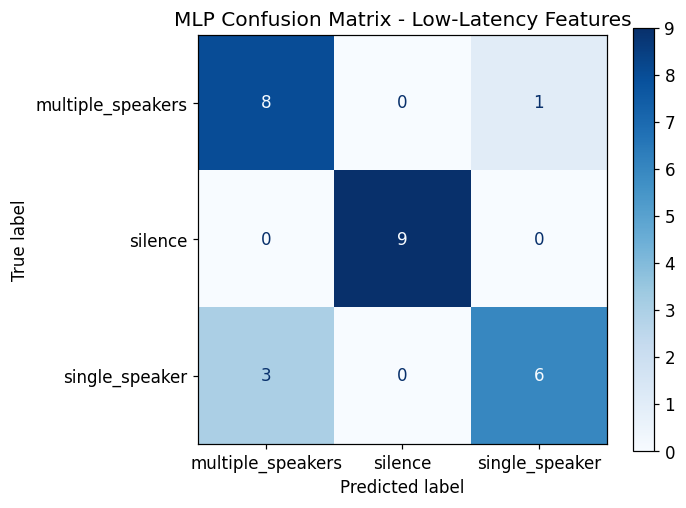

In [ ]:
# Confusion matrix

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("MLP Confusion Matrix - Low-Latency Features")
plt.grid(False)
plt.show()

### Section 7: Export weights.json

In [ ]:
import json

mlp = mlp_model.named_steps["mlp"]
scaler = mlp_model.named_steps["scaler"]

print("MLP layers:")
for i, w in enumerate(mlp.coefs_):
    print(f"Layer {i} weights shape:", w.shape)

for i, b in enumerate(mlp.intercepts_):
    print(f"Layer {i} bias shape:", b.shape)

MLP layers:
Layer 0 weights shape: (9, 8)
Layer 1 weights shape: (8, 3)
Layer 0 bias shape: (8,)
Layer 1 bias shape: (3,)


In [ ]:
export_dict = {
    "scaler": {
        "mean": scaler.mean_.tolist(),
        "scale": scaler.scale_.tolist(),
    },
    "model": {
        "weights": [w.tolist() for w in mlp.coefs_],
        "biases": [b.tolist() for b in mlp.intercepts_],
    },
    "label_map": {int(i): label for i, label in enumerate(label_encoder.classes_)},
    "feature_order": feature_cols,
    "model_type": "low_latency_1sec_temporal_mlp",
    "window_sec": 1.0,
    "stride_sec": 1.0,
    "n_subsegments": 10,
}

with open("mlp_model_export.json", "w") as f:
    json.dump(export_dict, f, indent=2)

print("Saved to mlp_model_export.json")
print("Feature order:", feature_cols)
print("Label map:", export_dict["label_map"])

Saved to mlp_model_export.json
Feature order: ['mean_abs_amp', 'rms_energy', 'peak_amp', 'variance', 'zero_crossing_rate', 'sub_rms_std', 'sub_rms_range', 'active_ratio', 'max_active_streak']
Label map: {0: 'multiple_speakers', 1: 'silence', 2: 'single_speaker'}


### Section 8: Output Verification

In [ ]:
import json
import numpy as np
import pandas as pd

with open("mlp_model_export.json", "r") as f:
    exported = json.load(f)

print(exported.keys())
print("Feature order:", exported["feature_order"])
print("Label map:", exported["label_map"])
print("Model type:", exported.get("model_type"))

dict_keys(['scaler', 'model', 'label_map', 'feature_order', 'model_type', 'window_sec', 'stride_sec', 'n_subsegments'])
Feature order: ['mean_abs_amp', 'rms_energy', 'peak_amp', 'variance', 'zero_crossing_rate', 'sub_rms_std', 'sub_rms_range', 'active_ratio', 'max_active_streak']
Label map: {'0': 'multiple_speakers', '1': 'silence', '2': 'single_speaker'}
Model type: low_latency_1sec_temporal_mlp


In [ ]:
def relu(x):
    return np.maximum(0, x)

def manual_mlp_predict_one(x_raw, exported):
    mean = np.array(exported["scaler"]["mean"])
    scale = np.array(exported["scaler"]["scale"])

    weights = [np.array(w) for w in exported["model"]["weights"]]
    biases = [np.array(b) for b in exported["model"]["biases"]]

    label_map = {int(k): v for k, v in exported["label_map"].items()}

    # StandardScaler
    x = (np.array(x_raw, dtype=float) - mean) / scale

    # MLP forward
    for layer_i in range(len(weights)):
        x = x @ weights[layer_i] + biases[layer_i]
        if layer_i < len(weights) - 1:
            x = relu(x)

    pred_id = int(np.argmax(x))
    pred_label = label_map[pred_id]

    return pred_id, pred_label, x

In [ ]:
# Compare manual prediction vs sklearn prediction

X_test_reset = X_test.reset_index(drop=True)

manual_preds = []
sklearn_preds = []

for i in range(len(X_test_reset)):
    x_raw = X_test_reset.loc[i, exported["feature_order"]].values

    manual_id, manual_label, logits = manual_mlp_predict_one(x_raw, exported)
    manual_preds.append(manual_id)

    sklearn_id = int(
        mlp_model.predict(
            X_test_reset.loc[[i], exported["feature_order"]]
        )[0]
    )
    sklearn_preds.append(sklearn_id)

manual_preds = np.array(manual_preds)
sklearn_preds = np.array(sklearn_preds)

match_rate = np.mean(manual_preds == sklearn_preds)

print("Manual vs sklearn match rate:", match_rate)
print("Number matched:", np.sum(manual_preds == sklearn_preds))
print("Total samples:", len(sklearn_preds))

Manual vs sklearn match rate: 1.0
Number matched: 27
Total samples: 27


In [ ]:
# Verification table

label_map = {int(k): v for k, v in exported["label_map"].items()}

verification_df = X_test_reset.copy()
verification_df["sklearn_pred_id"] = sklearn_preds
verification_df["manual_pred_id"] = manual_preds
verification_df["sklearn_pred_label"] = label_encoder.inverse_transform(sklearn_preds)
verification_df["manual_pred_label"] = [label_map[i] for i in manual_preds]
verification_df["match"] = verification_df["sklearn_pred_id"] == verification_df["manual_pred_id"]

verification_df[
    ["sklearn_pred_label", "manual_pred_label", "match"]
].head(15)

,sklearn_pred_label,manual_pred_label,match
0,multiple_speakers,multiple_speakers,True
1,single_speaker,single_speaker,True
2,multiple_speakers,multiple_speakers,True
3,multiple_speakers,multiple_speakers,True
4,single_speaker,single_speaker,True
5,silence,silence,True
6,multiple_speakers,multiple_speakers,True
7,silence,silence,True
8,multiple_speakers,multiple_speakers,True
9,multiple_speakers,multiple_speakers,True


In [ ]:
# Check mismatches

mismatch_df = verification_df[verification_df["match"] == False]

print("Number of mismatches:", len(mismatch_df))

mismatch_df[
    ["sklearn_pred_label", "manual_pred_label", "match"]
]

Number of mismatches: 0


,sklearn_pred_label,manual_pred_label,match
